# Data Preparation – CA1 KARIN ZAGAL 
## Student Dataset Analysis

**Español**

Este notebook analiza el conjunto de datos de estudiantes. El objetivo es caracterizar y preparar los datos, realizar análisis exploratorio (EDA), aplicar PCA para reducir la dimensionalidad conservando al menos el 99,5 % de la varianza y probar el conjunto reducido mediante agrupamiento K-Means.

**English**

This notebook analyses the student dataset. The objectives are to characterise and prepare the data, perform exploratory data analysis (EDA), apply PCA to reduce dimensionality while retaining at least 99.5% of the variance, and practically test the reduced dataset using K-Means clustering.

**Dataset file:** `student_dataV2(2).csv`

## 1. Import libraries and load the dataset

**Español:** Importamos pandas para trabajar con los datos y matplotlib para crear gráficos. El archivo CSV se encuentra en la misma carpeta que este notebook.

**English:** We import pandas to work with the data and matplotlib to create charts. The CSV file must be in the same folder as this notebook.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv("student_dataV2(2).csv")
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17.0,5.0,171.0,1,1,122.0,1,19,12.0,5.0,9,127.3,1,0,0.0,1,1,0,20,0.0,0,0,0,0,0.000000,0,0,0.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15.0,1.0,9254.0,1,1,160.0,1,1,3.0,3.0,3,142.5,1,0,0.0,0,1,0,19,0.0,0,6,6,6,14.000000,0,0,6.0,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1.0,5.0,9070.0,1,1,122.0,1,37,37.0,9.0,9,124.8,1,0,0.0,0,1,0,19,0.0,0,6,0,0,0.000000,0,0,6.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17.0,2.0,9773.0,1,1,122.0,1,38,37.0,5.0,3,119.6,1,0,0.0,1,0,0,20,0.0,0,6,8,6,13.428571,0,0,6.0,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39.0,1.0,8014.0,0,1,100.0,1,37,38.0,9.0,9,141.5,0,0,0.0,1,0,0,45,0.0,0,6,9,5,12.333333,0,0,6.0,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


## 2. Dataset characterisation

**Español:** Primero revisamos el número de observaciones y atributos, los tipos de datos, los valores ausentes y los registros duplicados. Estas comprobaciones permiten conocer la calidad y estructura inicial del conjunto de datos.

**English:** First, we check the number of observations and attributes, data types, missing values and duplicate records. These checks help us understand the initial structure and quality of the dataset.

In [2]:
df.shape

(4424, 37)

In [3]:
df.dtypes

Marital status                                     object
Application mode                                  float64
Application order                                 float64
Course                                            float64
Daytime/evening attendance                          int64
Previous qualification                              int64
Previous qualification (grade)                    float64
Nacionality                                        object
Mother's qualification                              int64
Father's qualification                            float64
Mother's occupation                               float64
Father's occupation                                object
Admission grade                                   float64
Displaced                                          object
Educational special needs                           int64
Debtor                                            float64
Tuition fees up to date                            object
Gender        

In [4]:
df.isnull().sum()

Marital status                                    0
Application mode                                  1
Application order                                 1
Course                                            3
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    4
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            1
Mother's occupation                               1
Father's occupation                               1
Admission grade                                   2
Displaced                                         0
Educational special needs                         0
Debtor                                            1
Tuition fees up to date                           1
Gender                                            0
Scholarship holder                                0
Age at enrol

In [5]:
missing_values = df.isnull().sum().sum()
total_cells = df.size
missing_percentage = (missing_values / total_cells) * 100

print("Total missing values:", missing_values)
print("Total cells:", total_cells)
print("Percentage of missing values:", round(missing_percentage, 4), "%")

Total missing values: 21
Total cells: 163688
Percentage of missing values: 0.0128 %


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.describe()

,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Mother's qualification,Father's qualification,Mother's occupation,Admission grade,Educational special needs,Debtor,Gender,Scholarship holder,International,Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4423.000000,4423.000000,4421.000000,4424.000000,4424.000000,4420.000000,4424.000000,4423.000000,4423.000000,4422.000000,4424.000000,4423.000000,4424.000000,4424.000000,4423.000000,4424.000000,4424.000000,4424.000000,4423.000000,4424.000000,4424.000000,4423.000000,4424.000000,4424.000000,4423.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,18.663351,1.727560,8856.331147,0.890823,4.577758,132.621561,19.561935,22.271987,10.961338,126.988512,0.011528,0.113724,0.351718,0.248418,0.024870,6.270570,8.299051,4.706600,10.640100,0.137658,0.541817,6.231743,8.063291,4.435805,10.229941,0.150316,11.566139,1.228029,0.001969
std,17.482509,1.313802,2064.221611,0.311897,10.216592,13.189209,15.603186,15.343244,26.421223,14.476775,0.106760,0.317511,0.477560,0.432144,0.155746,2.480178,4.179106,3.094238,4.843973,0.690880,1.918546,2.196038,3.947951,3.014764,5.211367,0.753774,2.663850,1.382711,2.269935
min,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,0.000000,95.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,2.000000,3.000000,4.000000,117.900000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,6.000000,3.000000,11.000000,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,19.000000,19.000000,5.000000,126.100000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,8.000000,5.000000,12.285714,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,37.000000,37.000000,9.000000,134.800000,0.000000,0.000000,1.000000,0.000000,0.000000,7.000000,10.000000,6.000000,13.399000,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,44.000000,44.000000,194.000000,190.000000,1.000000,1.000000,1.000000,1.000000,1.000000,26.000000,45.000000,26.000000,18.875000,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [8]:
df["Target"].value_counts()

Target
Graduate    2207
Dropout     1419
Enrolled     794
Grad           1
graduate       1
Drop           1
dropout        1
Name: count, dtype: int64

### Characterisation – interpretation

**Español**

El conjunto de datos contiene 4.424 observaciones y 37 atributos. Se identificaron 21 valores ausentes, equivalentes aproximadamente al 0,0128 % de todas las celdas. No se encontraron filas completamente duplicadas. La variable `Target` contiene tres resultados principales: Graduate, Dropout y Enrolled. También aparecen cuatro etiquetas escritas con variaciones de mayúsculas o abreviaciones, que se normalizan durante la limpieza.

**English**

The dataset contains 4,424 observations and 37 attributes. A total of 21 missing values were identified, representing approximately 0.0128% of all cells. No fully duplicated rows were found. The `Target` variable contains three main outcomes: Graduate, Dropout and Enrolled. Four additional labels contain capitalisation or abbreviation variations and are standardised during data cleaning.

## 3. Data preparation and cleaning

**Español:** Normalizamos las etiquetas de `Target` para que cada resultado tenga una sola escritura. Después eliminamos las filas que contienen valores ausentes. Esta decisión deja un conjunto completo para las comprobaciones posteriores; se debe tener presente que se eliminan observaciones.

**English:** We standardise the labels in `Target` so that each outcome has one consistent spelling. We then remove rows containing missing values. This produces a complete dataset for the following checks; the reduction in the number of observations should be acknowledged.

In [9]:
df["Target"] = df["Target"].replace({
    "Grad": "Graduate",
    "graduate": "Graduate",
    "Drop": "Dropout",
    "dropout": "Dropout"
})

df["Target"].value_counts()

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

In [10]:
df = df.dropna()
df.shape

(4405, 37)

In [11]:
df.isnull().sum().sum()

np.int64(0)

**Español:** Después de eliminar las filas con valores ausentes, quedan 4.405 observaciones y 37 atributos. La comprobación confirma que no quedan valores ausentes.

**English:** After removing rows with missing values, 4,405 observations and 37 attributes remain. The check confirms that no missing values remain.

## 4. Exploratory Data Analysis (EDA)

**Español:** Los diagramas de caja permiten observar la mediana, el rango intercuartílico, la dispersión y posibles valores atípicos. Se seleccionaron variables económicas y variables de rendimiento académico de ambos semestres porque ayudan a explorar el contexto del estudiante y su progreso académico.

**English:** Boxplots help us observe the median, interquartile range, dispersion and potential outliers. Economic indicators and academic performance variables from both semesters were selected because they help explore the students' context and academic progress.

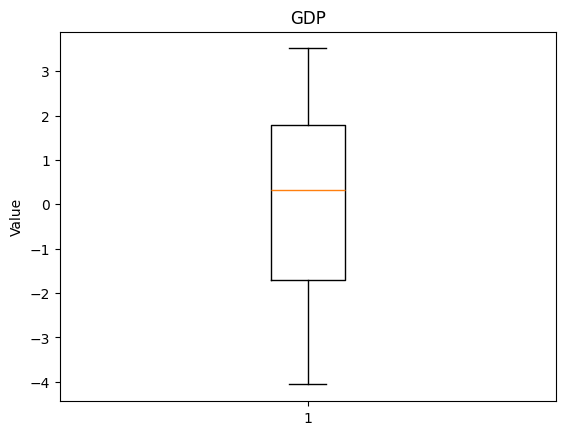

In [12]:
plt.boxplot(df["GDP"])
plt.title("GDP")
plt.ylabel("Value")
plt.show()

### GDP – Boxplot interpretation

**Español**

El diagrama de caja muestra la distribución de GDP. La mediana está ligeramente por encima de cero, aproximadamente en 0,32. El 50 % central de los valores se encuentra aproximadamente entre -1,70 y 1,79. Los bigotes se extienden aproximadamente desde -4,06 hasta 3,51. No se observan puntos individuales fuera de los bigotes.

**English**

The boxplot shows the distribution of GDP. The median is slightly above zero, at approximately 0.32. The central 50% of values lies approximately between -1.70 and 1.79. The whiskers extend approximately from -4.06 to 3.51. No individual points are visible beyond the whiskers.

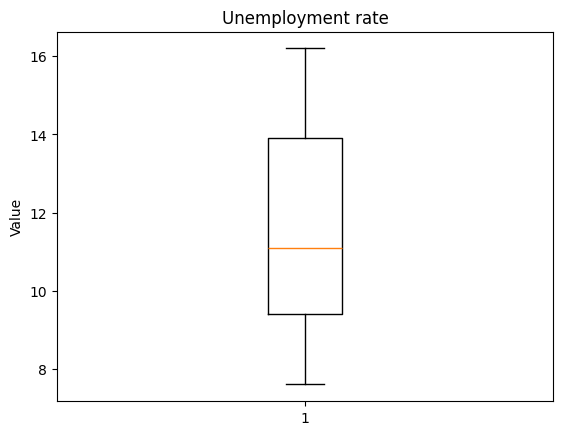

In [13]:
plt.boxplot(df["Unemployment rate"])
plt.title("Unemployment rate")
plt.ylabel("Value")
plt.show()

### Unemployment rate – Boxplot interpretation

**Español**

La mediana de la tasa de desempleo es aproximadamente 11,1. El 50 % central de los valores se encuentra entre 9,4 y 13,9. Los bigotes se extienden aproximadamente desde 7,6 hasta 16,2. El gráfico muestra variación en la tasa de desempleo y no presenta puntos individuales fuera de los bigotes.

**English**

The median unemployment rate is approximately 11.1. The central 50% of values lies between 9.4 and 13.9. The whiskers extend approximately from 7.6 to 16.2. The chart shows variation in the unemployment rate and no individual points beyond the whiskers.

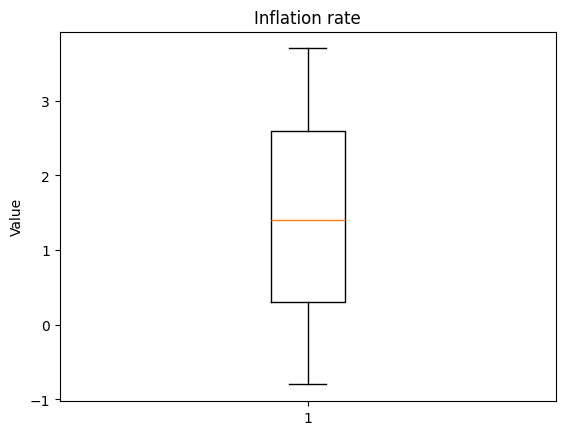

In [14]:
plt.boxplot(df["Inflation rate"])
plt.title("Inflation rate")
plt.ylabel("Value")
plt.show()

### Inflation rate – Boxplot interpretation

**Español**

La mediana de la tasa de inflación es aproximadamente 1,4. El 50 % central de los valores se encuentra entre 0,3 y 2,6. Los valores incluyen observaciones negativas y positivas, lo que muestra variación en la tasa de inflación durante los periodos representados. No se observan puntos individuales fuera de los bigotes.

**English**

The median inflation rate is approximately 1.4. The central 50% of values lies between 0.3 and 2.6. The values include both negative and positive observations, showing variation in the inflation rate across the represented periods. No individual points are visible beyond the whiskers.

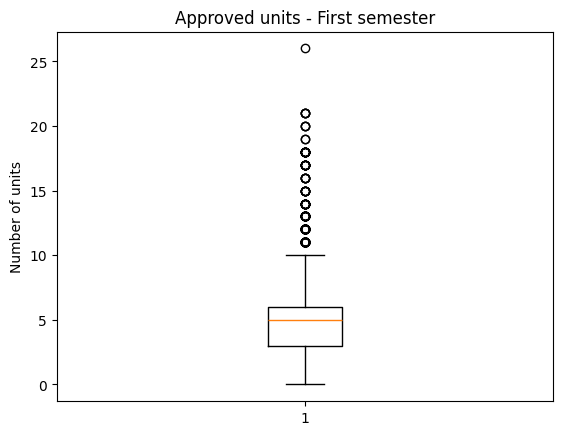

In [15]:
plt.boxplot(df["Curricular units 1st sem (approved)"])
plt.title("Approved units - First semester")
plt.ylabel("Number of units")
plt.show()

### Approved units – First semester

**Español**

El diagrama muestra que la mediana de unidades aprobadas en el primer semestre es aproximadamente 5. La mitad central de los estudiantes aprobó entre 3 y 6 unidades. Se observan varios valores altos por encima del bigote superior, que aparecen como posibles valores atípicos. Esto indica que algunos estudiantes aprobaron bastantes más unidades que la mayoría.

**English**

The boxplot shows that the median number of approved units in the first semester is approximately 5. The central half of students passed between 3 and 6 units. Several high values appear above the upper whisker as potential outliers. This indicates that some students passed considerably more units than most students.

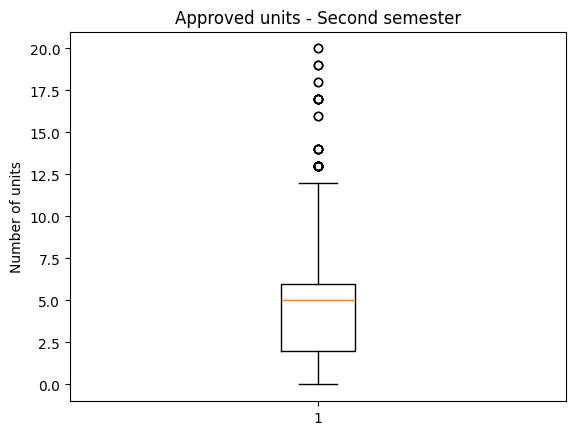

In [16]:
plt.boxplot(df["Curricular units 2nd sem (approved)"])
plt.title("Approved units - Second semester")
plt.ylabel("Number of units")
plt.show()

### Approved units – Second semester

**Español**

La mediana de unidades aprobadas en el segundo semestre también es aproximadamente 5. El 50 % central de los estudiantes aprobó entre 2 y 6 unidades. Se observan algunos valores altos por encima del bigote superior. La distribución es similar a la del primer semestre, aunque el rango intercuartílico del segundo semestre es algo más amplio.

**English**

The median number of approved units in the second semester is also approximately 5. The central 50% of students passed between 2 and 6 units. Some high values appear above the upper whisker. The distribution is similar to the first semester, although the second-semester interquartile range is slightly wider.

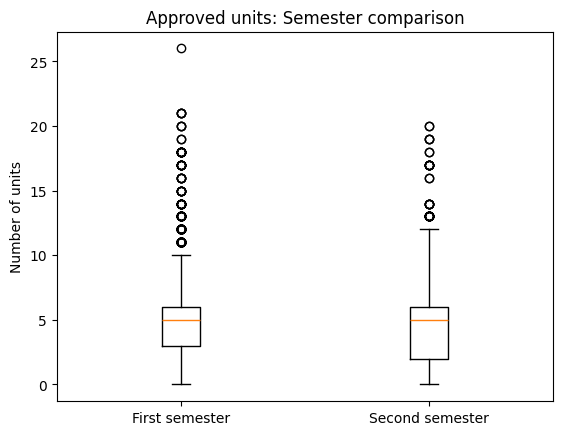

In [17]:
plt.boxplot([
    df["Curricular units 1st sem (approved)"],
    df["Curricular units 2nd sem (approved)"]
])
plt.title("Approved units: Semester comparison")
plt.ylabel("Number of units")
plt.xticks([1, 2], ["First semester", "Second semester"])
plt.show()

### Approved units – Semester comparison

**Español**

La comparación muestra que la mediana es aproximadamente 5 unidades en ambos semestres. El segundo semestre presenta un rango intercuartílico ligeramente más amplio. En los dos semestres aparecen valores altos que pueden considerarse atípicos. En general, el número típico de unidades aprobadas es parecido en ambos periodos.

**English**

The comparison shows a median of approximately 5 approved units in both semesters. The second semester has a slightly wider interquartile range. High values that may be considered outliers appear in both semesters. Overall, the typical number of approved units is similar in both periods.

## 5. Principal Component Analysis (PCA)

**Español:** Para PCA se utilizaron las 36 variables predictoras del conjunto de datos, excluyendo `Target`, que es la variable objetivo y se conserva separada para la interpretación posterior. Las variables se convirtieron a formato numérico; los valores no válidos se trataron como ausentes y se eliminaron las observaciones incompletas para este análisis. Después, se estandarizaron las variables porque están medidas en escalas diferentes.

**English:** PCA was applied to all 36 predictor features in the dataset, excluding `Target`, which is the dependent variable and is kept separate for subsequent interpretation. The variables were converted to numeric format; invalid values were treated as missing and incomplete observations were removed for this analysis. The features were then standardised because they use different scales.


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Use all 36 predictor features; keep Target out of PCA
pca_data = df.drop(columns=['Target']).replace('?', np.nan).apply(pd.to_numeric, errors='coerce')
pca_data = pca_data.dropna()
print('PCA data shape:', pca_data.shape)


PCA data shape: (4399, 36)


**Español:** Después de convertir las 36 variables predictoras a formato numérico y eliminar las observaciones con valores no válidos o ausentes, quedaron 4.399 observaciones y 36 variables para PCA. `Target` no se incluyó en el cálculo para evitar utilizar la respuesta que posteriormente se desea analizar.

**English:** After converting all 36 predictor features to numeric format and removing observations with invalid or missing values, 4,399 observations and 36 features remained for PCA. `Target` was not included in the calculation to avoid using the outcome that is analysed later.


In [ ]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(pca_data)
print('Scaled data shape:', scaled_data.shape)


Scaled data shape: (4399, 36)


In [ ]:
pca_full = PCA()
pca_full.fit(scaled_data)

cumulative_variance = pca_full.explained_variance_ratio_.cumsum()
print(pd.Series(cumulative_variance, index=range(1, len(cumulative_variance)+1)).to_string())


1     0.176613
2     0.275506
3     0.334173
4     0.390086
5     0.442702
6     0.489334
7     0.533549
8     0.576201
9     0.612095
10    0.646463
11    0.676727
12    0.704798
13    0.732219
14    0.758168
15    0.782427
16    0.805015
17    0.827013
18    0.847297
19    0.864978
20    0.881293
21    0.896876
22    0.911668
23    0.924555
24    0.937154
25    0.948628
26    0.959290
27    0.968129
28    0.974775
29    0.980582
30    0.985875
31    0.990580
32    0.993481
33    0.996019
34    0.998436
35    0.999420
36    1.000000


In [ ]:
pca = PCA(n_components=0.995)
reduced_data = pca.fit_transform(scaled_data)

print('Reduced data shape:', reduced_data.shape)
print('Number of components:', pca.n_components_)
print('Variance retained (%):', sum(pca.explained_variance_ratio_) * 100)


Reduced data shape: (4399, 33)
Number of components: 33
Variance retained (%): 99.60191570403693


### PCA results

**Español**

PCA redujo las 36 variables predictoras originales a 33 componentes principales y conservó aproximadamente el 99,60 % de la varianza. Se supera así el requisito mínimo del 99,5 %. La reducción es de tres dimensiones, por lo que se mantiene la mayor parte de la información, aunque la reducción dimensional es moderada.

**English**

PCA reduced the 36 original predictor features to 33 principal components and retained approximately 99.60% of the variance. This exceeds the minimum requirement of 99.5%. The reduction is three dimensions, so most of the information is preserved, although the dimensionality reduction is modest.

## 6. Curse of Dimensionality

**Español**

La maldición de la dimensionalidad describe los problemas que pueden aparecer cuando un conjunto de datos tiene muchas variables. A medida que aumenta el número de dimensiones, los datos pueden quedar más dispersos y las distancias entre observaciones pueden resultar menos útiles para identificar similitudes. Esto puede dificultar el análisis, aumentar el coste computacional y afectar a métodos basados en distancias o agrupamientos.

En este trabajo se utilizaron las 36 variables predictoras disponibles (excluyendo `Target`). PCA las redujo a 33 componentes, conservando el 99,60 % de la varianza. Aunque se cumple el umbral solicitado, la reducción es moderada: se eliminan tres dimensiones, por lo que parte de la complejidad del conjunto de datos permanece.

**English**

The Curse of Dimensionality describes problems that can occur when a dataset contains many features. As the number of dimensions increases, data can become more dispersed and distances between observations may become less useful for identifying similarities. This can make analysis more difficult, increase computational cost and affect distance-based or clustering methods.

In this assignment, all 36 available predictor features were used (excluding `Target`). PCA reduced them to 33 components while retaining 99.60% of the variance. Although the requested threshold was achieved, the reduction is moderate: only three dimensions were removed, so some complexity remains in the dataset.


## 7. Practical testing of the reduced dataset using K-Means

**Español:** Para probar el conjunto reducido, utilizamos K-Means con tres grupos, porque `Target` contiene tres resultados principales. K-Means es un método no supervisado: crea grupos según similitudes en los datos, pero no aprende directamente las etiquetas Graduate, Dropout y Enrolled. Por eso, la tabla cruzada sirve para comparar los grupos con las categorías reales, no para calcular precisión de clasificación.

**English:** To test the reduced dataset, we use K-Means with three clusters because `Target` contains three main outcomes. K-Means is an unsupervised method: it creates groups based on similarities in the data, but it does not directly learn the Graduate, Dropout and Enrolled labels. Therefore, the cross-tabulation compares clusters with the actual categories; it does not calculate classification accuracy.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

target = df.loc[pca_data.index, 'Target']

X_train, X_test, y_train, y_test = train_test_split(
    reduced_data, target, test_size=0.2, random_state=42
)

print('Training set:', X_train.shape)
print('Test set:', X_test.shape)


Training set: (3519, 33)
Test set: (880, 33)


In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X_train)

clusters = kmeans.predict(X_test)
pd.crosstab(y_test, clusters)


col_0       0    1   2
Target                
Dropout   137  118  16
Enrolled   13  144   6
Graduate   15  401  30


In [ ]:
silhouette = silhouette_score(X_test, clusters)
print('Silhouette Score:', silhouette)


Silhouette Score: 0.21983586794437313


### Testing results and discussion

**Español**

La división de los datos produjo 3,519 observaciones para entrenamiento y 880 para prueba, cada una representada por 33 componentes principales. K-Means asignó los registros de prueba a tres grupos. La tabla cruzada permite observar cómo se distribuyen las categorías reales (`Target`) entre los grupos; los clusters no deben interpretarse como predicciones directas de las categorías.

El Silhouette Score obtenido fue aproximadamente 0.2198. Este valor indica una separación limitada entre los grupos: existe cierta estructura, pero también solapamiento entre clusters. No representa precisión de predicción, porque K-Means es un algoritmo no supervisado.

**English**

The data split produced 3,519 observations for training and 880 for testing, each represented by 33 principal components. K-Means assigned the test records to three clusters. The cross-tabulation shows how the actual `Target` categories are distributed across the groups; the clusters should not be interpreted as direct predictions of the categories.

The Silhouette Score was approximately 0.2198. This indicates limited separation between the groups: some structure exists, but there is also overlap between clusters. It is not prediction accuracy because K-Means is an unsupervised algorithm.


## 8. Conclusions

**Español**

El análisis permitió caracterizar y preparar el conjunto de datos de estudiantes. El archivo original contenía 4.424 observaciones y 37 atributos, con valores ausentes y sin filas completamente duplicadas. Después de la preparación general, se conservaron los registros válidos para los análisis correspondientes.

Para PCA se utilizaron las 36 variables predictoras, excluyendo `Target`. Tras convertirlas a formato numérico y retirar las observaciones con valores no válidos o ausentes, quedaron 4,399 observaciones. PCA redujo las 36 variables a 33 componentes y conservó aproximadamente 99.60% de la varianza, superando el umbral requerido del 99,5%.

Finalmente, K-Means formó tres grupos. El Silhouette Score de aproximadamente 0.2198 indicó una separación limitada. En conjunto, PCA conservó la mayor parte de la información, aunque la reducción dimensional fue moderada y el agrupamiento no separó claramente los resultados académicos.

**English**

The analysis allowed the student dataset to be characterised and prepared. The original file contained 4,424 observations and 37 attributes, with missing values and no fully duplicated rows. After the general preparation, valid records were retained for the relevant analyses.

For PCA, all 36 predictor features were used, excluding `Target`. After numeric conversion and removal of observations with invalid or missing values, 4,399 observations remained. PCA reduced the 36 features to 33 components and retained approximately 99.60% of the variance, exceeding the required 99.5% threshold.

Finally, K-Means created three clusters. The Silhouette Score of approximately 0.2198 indicated limited separation. Overall, PCA retained most of the information, although dimensionality reduction was moderate and clustering did not clearly separate the academic outcomes.


## 9. References

- Realinho, V., Machado, J., Baptista, L. and Martins, M.V. (2022) ‘Predict students’ dropout and academic success’, *Data*, 7(11), 146.
- UCI Machine Learning Repository (2021) *Predict students’ dropout and academic success*. Available at: https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success (Accessed: 8 November 2026).
- scikit-learn developers (n.d.) *scikit-learn: Machine Learning in Python – User Guide*. Available at: https://scikit-learn.org/stable/user_guide.html (Accessed: 8 November 2026).
- pandas development team (n.d.) *pandas documentation*. Available at: https://pandas.pydata.org/docs/ (Accessed: 8 November 2026).
- Matplotlib development team (n.d.) *Matplotlib documentation*. Available at: https://matplotlib.org/stable/ (Accessed: 8 November 2026).

